# Predicting hospital readmission among patients with diabetes

**Final result:** Retained logistic regression after a modest forest improvement on validation. Reserved-test ROC AUC **0.657**; top-20% review captured **38.9%** of recorded readmissions with **18.9%** precision. Patient-bootstrap intervals and limitations appear in Stage 5. Earlier sections show the project's development in order.


## Stage 1: Understand the data

**Question:** Can information available by discharge predict a recorded inpatient readmission in **less than 30 days**?

This is a prediction project, not an evaluation of treatment effects. The source label is `<30`, not a verified inclusive 30-day endpoint. `NO` means no recorded readmission, not proof that no readmission occurred elsewhere.

The UCI release covers 1999â€“2008. Results will describe this historical dataset and will not establish present-day clinical performance.

We will build one concise case-study notebook incrementally. This stage audits the raw release; it does not select features, fit models, or estimate model performance.

In [29]:
from pathlib import Path
import hashlib
import zipfile

import pandas as pd

DATA_PATH = Path("data/raw/uci_diabetes.zip")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place the original UCI archive at data/raw/uci_diabetes.zip")

print("Archive SHA256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
with zipfile.ZipFile(DATA_PATH) as archive:
    print("Archive files:", archive.namelist())
    # The source uses ? for missing values; retain other literal categories.
    encounters = pd.read_csv(archive.open("diabetic_data.csv"), na_values=["?"], keep_default_na=False, low_memory=False)
    disposition_text = archive.read("IDS_mapping.csv").decode("utf-8-sig")

# One row must identify one encounter; patients may have several encounters.
assert encounters["encounter_id"].is_unique
assert encounters["patient_nbr"].notna().all()
assert set(encounters["readmitted"].unique()) == {"<30", ">30", "NO"}
print(f"Encounters: {len(encounters):,}")
print(f"Patients: {encounters['patient_nbr'].nunique():,}")
print(f"Columns: {encounters.shape[1]}")

Archive SHA256: f82ac129da2ddd2299391ff6fbae3a6a58b3edcf59ac9d7bd480c00fe453112a
Archive files: ['diabetic_data.csv', 'IDS_mapping.csv']
Encounters: 101,766
Patients: 71,518
Columns: 50


## Outcome and repeated patients

For the eventual binary task, `<30` is positive; `>30` and `NO` are negative under the recorded-label definition. Counts below describe the raw release, before eligibility exclusions.

Identifiers will not be model predictors. Patient IDs will define disjoint training, validation, and test groups so repeated encounters cannot appear across groups. We will not infer chronology from encounter IDs.

In [31]:
label_summary = encounters["readmitted"].value_counts().to_frame("encounters")
label_summary["percent"] = 100 * label_summary["encounters"] / len(encounters)
print(label_summary.round(2).to_string())

# Repeated patients must stay together when we later partition the data.
encounters_per_patient = encounters.groupby("patient_nbr").size()
print("Patients with multiple encounters:", int((encounters_per_patient > 1).sum()))
print("Maximum encounters per patient:", int(encounters_per_patient.max()))
print("Exact duplicated rows:", int(encounters.duplicated().sum()))

            encounters  percent
readmitted                     
NO               54864    53.91
>30              35545    34.93
<30              11357    11.16
Patients with multiple encounters: 16773
Maximum encounters per patient: 40
Exact duplicated rows: 0


## Missingness and discharge eligibility

`?` is treated as missing. Literal `None` values are preserved rather than automatically converted to missing values. Special codes such as `None` in laboratory results require separate interpretation; they may mean a test was not performed rather than an absent value.

Before modeling, review disposition mappings and define eligible discharges. Death, hospice, and transfer records need explicit handling because they change whether a new inpatient readmission is meaningful. Do not treat the raw cohort as the final modeling sample.

In [33]:
# This audit counts explicit missing values, not all special category codes.
missing_percent = encounters.isna().mean().mul(100).sort_values(ascending=False)
print("Columns with missing values (%):")
print(missing_percent[missing_percent > 0].round(2).to_string())
print("\nDischarge disposition counts:")
print(encounters["discharge_disposition_id"].value_counts().sort_index().to_string())
print("\nSource code mappings:\n")
print(disposition_text)

Columns with missing values (%):
weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02

Discharge disposition counts:
discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139

Source code mappings:

admission_type_id,description
1,Emergency
2,Urgent
3,Elective
4,Newborn
5,Not Available
6,NULL
7,Trauma Center
8,Not Mapped
,
discharge_disposition_id,description
1,Discharged to home
2,Discharged/transferred to another short term hospital
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpatient care institution
6,Discharge

## Modeling design principles

1. Define eligible discharges using the source mappings and document exclusion counts.
2. Audit candidate predictors for availability at discharge; exclude IDs and outcome-derived information.
3. Create fixed patient-disjoint training, validation, and test partitions. Learn preprocessing only on training data. Keep the test outcomes untouched until final evaluation.
4. Start with a prevalence baseline and logistic regression, then compare one tree-based model.
5. Evaluate average precision, ROC AUC, calibration, and recall/precision at a validation-selected follow-up capacity. Accuracy alone can hide poor performance on the minority outcome.

Patient separation evaluates generalization to unseen patients in this dataset. It does not demonstrate future-year or new-hospital performance; the release does not provide the dates and hospital IDs needed for those validation designs. Repeated test encounters also require patient-aware uncertainty estimates.

A Tableau companion can later summarize aggregate cohort and held-out evaluation results. No patient-level records will be included in dashboard exports.

**Source:** [UCI Diabetes 130-US Hospitals](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008), Clore et al. (2014), DOI 10.24432/C5230J, CC BY 4.0.

# Stage 2: Define the cohort and reserve evaluation data

**Focused question:** Among encounters ending in discharge home, can information available by discharge predict a recorded inpatient readmission in less than 30 days?

For this first portfolio model we choose an explicit **home-discharge cohort**: codes **1** (home), **6** (home with home health services), and **8** (home with an IV provider). All ages are retained. Code 7 (left against medical advice) is excluded because its destination is not specified. This is a scope choice, not a universal readmission eligibility standard.

Deaths and hospice are excluded. Facility transfers, other destinations, and unknown statuses are also excluded. Excluding skilled nursing and rehabilitation discharges narrows generalizability; it does not imply that those patients cannot be readmitted. The model will apply to eligible encounters, with repeated encounters retained.

The target is the source-recorded `<30` label. We cannot establish complete follow-up, distinguish planned from unplanned readmissions, or implement a claims-based quality measure from this release.

In [36]:
from sklearn.model_selection import GroupShuffleSplit

# Use documented category codes, not numerical thresholds or inferred rankings.
HOME_CODES = {1, 6, 8}
DEATH_CODES = {11, 19, 20, 21}
HOSPICE_CODES = {13, 14}
UNKNOWN_CODES = {18, 25, 26}

disposition = encounters["discharge_disposition_id"]
eligibility_reason = pd.Series("Other destination or status", index=encounters.index)
eligibility_reason.loc[disposition.isin(DEATH_CODES)] = "Death"
eligibility_reason.loc[disposition.isin(HOSPICE_CODES)] = "Hospice"
eligibility_reason.loc[disposition.isin(UNKNOWN_CODES) | disposition.isna()] = "Unknown status"
eligibility_reason.loc[disposition.isin(HOME_CODES)] = "Included: discharge home"

# These mutually exclusive counts reconcile to the entire source release.
cohort_flow = eligibility_reason.value_counts().rename_axis("eligibility").to_frame("encounters")
assert cohort_flow["encounters"].sum() == len(encounters)
print(cohort_flow.to_string())

cohort = encounters.loc[disposition.isin(HOME_CODES)].copy()
cohort["readmitted_under_30"] = cohort["readmitted"].eq("<30").astype("int8")
assert len(cohort) > 0
assert cohort["encounter_id"].is_unique
assert cohort["readmitted_under_30"].isin([0, 1]).all()
print(f"\nEligible encounters: {len(cohort):,}")
print(f"Eligible patients: {cohort['patient_nbr'].nunique():,}")

                             encounters
eligibility                            
Included: discharge home          73244
Other destination or status       21419
Unknown status                     4680
Death                              1652
Hospice                             771

Eligible encounters: 73,244
Eligible patients: 54,932


## Patient-disjoint partitions

Randomly allocate approximately 60% of **patients** to training, 20% to validation, and 20% to testing. Encounter proportions may differ because patients have different numbers of encounters. Use a fixed seed, without searching for a favorable split or stratifying on outcomes.

The training set will fit preprocessing and models. Validation will choose model settings and an operating threshold. Test labels will not be summarized or used for those choices. Stage 1 already inspected overall raw outcome frequencies; the test set is reserved now, before model development, rather than being an independently collected external sample.

The local partition manifest records the assignment for reproducibility. It contains identifiers and is excluded from Git.

In [38]:
# GroupShuffleSplit keeps every encounter for a patient in the same partition.
first_split = GroupShuffleSplit(n_splits=1, test_size=0.40, random_state=42)
train_positions, held_positions = next(
    first_split.split(cohort, groups=cohort["patient_nbr"])
)
held = cohort.iloc[held_positions]
second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=43)
validation_positions, test_positions = next(
    second_split.split(held, groups=held["patient_nbr"])
)

train = cohort.iloc[train_positions].copy()
validation = held.iloc[validation_positions].copy()
test = held.iloc[test_positions].copy()
partitions = {"train": train, "validation": validation, "test": test}

# Fail immediately if any patient or encounter appears in two partitions.
patient_sets = {name: set(frame["patient_nbr"]) for name, frame in partitions.items()}
assert patient_sets["train"].isdisjoint(patient_sets["validation"])
assert patient_sets["train"].isdisjoint(patient_sets["test"])
assert patient_sets["validation"].isdisjoint(patient_sets["test"])
combined_ids = pd.concat([frame["encounter_id"] for frame in partitions.values()])
assert combined_ids.is_unique
assert set(combined_ids) == set(cohort["encounter_id"])

split_summary = pd.DataFrame([
    {"partition": name, "encounters": len(frame), "patients": frame["patient_nbr"].nunique()}
    for name, frame in partitions.items()
])
print(split_summary.to_string(index=False))
# Only describe training outcomes; reserve validation/test for later evaluation.
print(f"\nTraining readmission rate: {train['readmitted_under_30'].mean():.2%}")

local_dir = Path("data/processed")
local_dir.mkdir(parents=True, exist_ok=True)
manifest = pd.concat([
    frame[["encounter_id", "patient_nbr"]].assign(partition=name)
    for name, frame in partitions.items()
], ignore_index=True)
manifest.to_csv(local_dir / "partition_manifest.csv", index=False)

# Reports contain aggregate counts only and may be shared with the portfolio.
report_dir = Path("reports")
report_dir.mkdir(exist_ok=True)
cohort_flow.to_csv(report_dir / "cohort_flow.csv")
split_summary.to_csv(report_dir / "partition_summary.csv", index=False)

 partition  encounters  patients
     train       44065     32959
validation       14526     10986
      test       14653     10987

Training readmission rate: 10.11%


## Initial predictor plan

Use a small, interpretable starting set rather than every column. Age and admission codes are categorical; activity and history counts are numeric. Encounter-total counts are appropriate only for the stated **discharge-time** prediction, not admission-time prediction. Their exact production-system availability is not independently verified here.

Start with age, admission type/source, length of stay, counts of laboratory procedures, procedures, medications and diagnoses, and prior-year outpatient, emergency and inpatient encounters. IDs, readmission labels and all derived outcome fields are excluded. Discharge disposition defines eligibility and will not be a baseline predictor. Race and gender are reserved for later descriptive performance checks; omitting them does not itself establish fairness.

Hold detailed diagnosis codes, medication categories and highly incomplete fields out of this first baseline. We may consider documented additions using training and validation data later. Fit imputation, encoding and scaling on training data only.

**Next:** Fit a prevalence baseline and a logistic regression pipeline. No predictive performance has been estimated yet.

In [40]:
CATEGORICAL_FEATURES = ["age", "admission_type_id", "admission_source_id"]
NUMERIC_FEATURES = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_diagnoses",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
FORBIDDEN_FEATURES = {"encounter_id", "patient_nbr", "readmitted", "readmitted_under_30"}
assert set(FEATURES).issubset(cohort.columns)
assert not set(FEATURES).intersection(FORBIDDEN_FEATURES)
assert train[NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce").notna().all().all()
print("Baseline predictors:", len(FEATURES))
print("Stage 2 patient overlap and predictor checks passed.")

Baseline predictors: 11
Stage 2 patient overlap and predictor checks passed.


# Stage 3: First predictive model

We now compare two models using the fixed partitions from Stage 2:

- **Prevalence baseline:** assign every encounter the readmission probability observed in training. This learns no patient-specific patterns.
- **Logistic regression:** use the 11 planned predictors to estimate individual encounter risk. Start with fixed L2 regularization (`C=1`), without hyperparameter searches, oversampling or class weighting.

All imputation, scaling, encoding and model coefficients are fitted using **training data only**. Numeric admission codes are explicitly routed through categorical encoding, so the model does not treat code magnitudes as ordered severity. The median fills missing numeric values; the most frequent training category fills missing categorical values. Unknown categories at evaluation time are handled without refitting.

**Before reviewing validation outcomes**, specify an illustrative follow-up capacity of **20% of eligible discharge encounters**. This is a portfolio scenario, not a measured hospital capacity or an optimized clinical policy. We will assess how many recorded readmissions fall within that highest-scoring fifth. Validation data guide further development; test outcomes remain reserved.

In [42]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

FOLLOW_UP_FRACTION = 0.20  # Set before examining validation performance.
TARGET = "readmitted_under_30"
X_train = train[FEATURES]
y_train = train[TARGET]
X_validation = validation[FEATURES]
y_validation = validation[TARGET]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, solver="lbfgs")),
])
baseline_model = DummyClassifier(strategy="prior")

# Pipeline.fit learns every preprocessing step from training records only.
# Fail visibly rather than accepting a model that did not converge.
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    logistic_model.fit(X_train, y_train)
baseline_model.fit(X_train, y_train)

validation_probabilities = {
    "Prevalence baseline": baseline_model.predict_proba(X_validation)[:, 1],
    "Logistic regression": logistic_model.predict_proba(X_validation)[:, 1],
}
for probabilities in validation_probabilities.values():
    assert len(probabilities) == len(validation)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
assert np.allclose(validation_probabilities["Prevalence baseline"], y_train.mean())
print("Fitted models using training data only.")
print("Transformed predictor columns:", len(preprocessor.get_feature_names_out()))
print("Logistic optimizer iterations:", logistic_model["classifier"].n_iter_[0])

Fitted models using training data only.
Transformed predictor columns: 43
Logistic optimizer iterations: 55


## Compare validation performance

The positive outcome is relatively uncommon, so accuracy alone can be misleading.

| Measure | Interpretation | Better direction |
|---|---|---|
| Average precision | Summarizes precision across recall levels; useful for uncommon outcomes | Higher |
| ROC AUC | How well scores rank recorded readmissions above other encounters | Higher |
| Brier score | Mean squared error of predicted probabilities | Lower |
| Log loss | Probability error that penalizes confident mistakes | Lower |

A constant-score baseline has average precision equal to validation prevalence and ROC AUC of 0.5. Brier score and log loss measure overall probability quality, not calibration alone. The reliability plot below checks calibration more directly.

These are encounter-weighted results: patients with more eligible encounters contribute more rows. This first comparison uses one validation split and has no uncertainty intervals; it is not a final held-out performance claim.

In [44]:
validation_metrics = pd.DataFrame([
    {
        "model": model_name,
        "average_precision": average_precision_score(y_validation, probabilities),
        "roc_auc": roc_auc_score(y_validation, probabilities),
        "brier_score": brier_score_loss(y_validation, probabilities),
        "log_loss": log_loss(y_validation, probabilities, labels=[0, 1]),
    }
    for model_name, probabilities in validation_probabilities.items()
])
print(validation_metrics.round(4).to_string(index=False))
print(f"\nValidation recorded readmission rate: {y_validation.mean():.2%}")
print(f"Always predicting no readmission would achieve {1 - y_validation.mean():.2%} accuracy")
print("while identifying none of the recorded readmissions.")
validation_metrics.to_csv(report_dir / "validation_model_metrics.csv", index=False)

              model  average_precision  roc_auc  brier_score  log_loss
Prevalence baseline             0.0945    0.500       0.0856    0.3131
Logistic regression             0.1736    0.631       0.0834    0.3025

Validation recorded readmission rate: 9.45%
Always predicting no readmission would achieve 90.55% accuracy
while identifying none of the recorded readmissions.


## Illustrative follow-up capacity

Rank validation encounters by predicted risk and flag exactly the highest-scoring 20%, rounding the number reviewed up. Break any score ties using encounter ID solely as a deterministic tie-breaker; the ID is never a model input.

**Precision** is the recorded readmission rate among flagged encounters. **Recall** is the fraction of all recorded readmissions that were flagged. **Lift** compares that precision with the overall validation rate. Randomly reviewing the same number of encounters has expected precision equal to overall prevalence and expected recall equal to the fraction reviewed.

The lowest flagged score is reported for context. A fixed probability cutoff can select a different fraction in a new population and may include extra tied scores. This capacity-based ranking is not yet a deployment threshold, does not measure prevented readmissions, and has no assumed treatment benefit.

In [46]:
# Preserve row alignment explicitly before sorting probabilities and outcomes.
ranked_validation = validation[["encounter_id", TARGET]].copy()
ranked_validation["predicted_probability"] = validation_probabilities["Logistic regression"]
ranked_validation = ranked_validation.sort_values(
    ["predicted_probability", "encounter_id"], ascending=[False, True]
)
review_count = int(np.ceil(FOLLOW_UP_FRACTION * len(ranked_validation)))
flagged = ranked_validation.iloc[:review_count]
true_positives = int(flagged[TARGET].sum())
false_positives = review_count - true_positives
total_readmissions = int(y_validation.sum())
false_negatives = total_readmissions - true_positives
true_negatives = len(validation) - review_count - false_negatives
assert true_positives + false_positives + false_negatives + true_negatives == len(validation)

capacity_summary = pd.DataFrame([{
    "evaluation_set": "validation",
    "reviewed_encounters": review_count,
    "reviewed_fraction": review_count / len(validation),
    "true_positives": true_positives,
    "false_positives": false_positives,
    "false_negatives": false_negatives,
    "true_negatives": true_negatives,
    "precision": true_positives / review_count,
    "recall": true_positives / total_readmissions,
    "precision_lift": (true_positives / review_count) / y_validation.mean(),
    "lowest_flagged_score": flagged["predicted_probability"].min(),
    "random_review_expected_true_positives": review_count * y_validation.mean(),
    "random_review_expected_precision": y_validation.mean(),
    "random_review_expected_recall": review_count / len(validation),
}])
print(capacity_summary.T.round(4).to_string(header=False))
capacity_summary.to_csv(report_dir / "validation_capacity_summary.csv", index=False)
# Do not export encounter scores or identifiers as public reports.

evaluation_set                         validation
reviewed_encounters                          2906
reviewed_fraction                        0.200055
true_positives                                481
false_positives                              2425
false_negatives                               892
true_negatives                              10728
precision                                 0.16552
recall                                   0.350328
precision_lift                           1.751157
lowest_flagged_score                     0.112956
random_review_expected_true_positives  274.675616
random_review_expected_precision          0.09452
random_review_expected_recall            0.200055


## Ranking and calibration plots

The precision-recall curve asks how concentrated recorded readmissions are near the top of the ranking. The ROC curve provides a complementary ranking view. Neither shows whether a predicted 20% risk corresponds to an observed rate near 20%.

The reliability plot groups validation predictions into up to ten similarly sized bins and compares mean predicted probability with observed readmission frequency. Points near the diagonal indicate agreement in those bins. This is a diagnostic, not an additional calibration fit or proof of calibration in future populations.

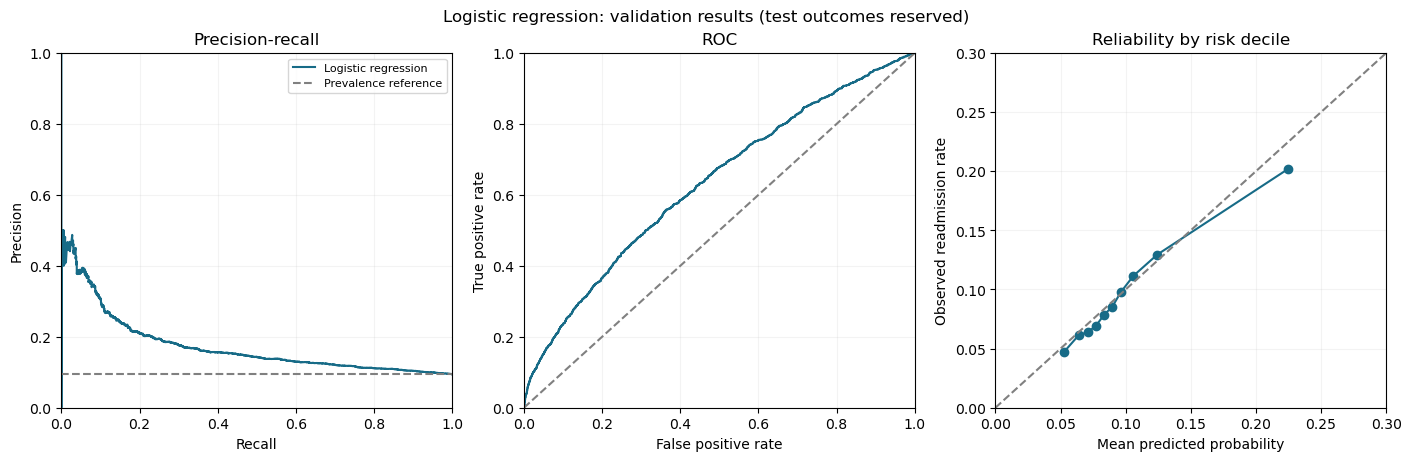

 encounters  readmissions  mean_predicted_probability  observed_readmission_rate
       1453            68                      0.0524                     0.0468
       1453            89                      0.0639                     0.0613
       1452            93                      0.0708                     0.0640
       1453           100                      0.0769                     0.0688
       1452           114                      0.0833                     0.0785
       1453           124                      0.0897                     0.0853
       1452           142                      0.0963                     0.0978
       1453           162                      0.1059                     0.1115
       1452           188                      0.1242                     0.1295
       1453           293                      0.2243                     0.2017


In [48]:
probabilities = validation_probabilities["Logistic regression"]
calibration_records = pd.DataFrame({"probability": probabilities, "outcome": y_validation.to_numpy()})
# Quantile bins avoid almost-empty bins when most estimated risks are low.
calibration_records["bin"] = pd.qcut(calibration_records["probability"], q=10, duplicates="drop")
calibration_summary = calibration_records.groupby("bin", observed=True).agg(
    encounters=("outcome", "size"),
    readmissions=("outcome", "sum"),
    mean_predicted_probability=("probability", "mean"),
    observed_readmission_rate=("outcome", "mean"),
).reset_index(drop=True)
assert calibration_summary["encounters"].sum() == len(validation)
calibration_summary.to_csv(report_dir / "validation_calibration_bins.csv", index=False)

precision, recall, _ = precision_recall_curve(y_validation, probabilities)
false_positive_rate, true_positive_rate, _ = roc_curve(y_validation, probabilities)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
color = "#176B87"
axes[0].plot(recall, precision, color=color, label="Logistic regression")
axes[0].axhline(y_validation.mean(), color="gray", linestyle="--", label="Prevalence reference")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=8)
axes[1].plot(false_positive_rate, true_positive_rate, color=color)
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC", xlim=(0, 1), ylim=(0, 1))

calibration_limit = min(1.0, max(
    0.30,
    calibration_summary["mean_predicted_probability"].max() * 1.15,
    calibration_summary["observed_readmission_rate"].max() * 1.15,
))
axes[2].plot(
    calibration_summary["mean_predicted_probability"],
    calibration_summary["observed_readmission_rate"],
    marker="o", color=color,
)
axes[2].plot([0, calibration_limit], [0, calibration_limit], color="gray", linestyle="--")
axes[2].set(
    xlabel="Mean predicted probability", ylabel="Observed readmission rate",
    title="Reliability by risk decile", xlim=(0, calibration_limit), ylim=(0, calibration_limit),
)
for axis in axes:
    axis.grid(alpha=0.15)
fig.suptitle("Logistic regression: validation results (test outcomes reserved)")
figure_path = report_dir / "validation_performance.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print(calibration_summary.round(4).to_string(index=False))

## Interpretation and next step

The following summary is generated from the validation results. It does not establish clinical usefulness, preventability, intervention effectiveness, or performance on new hospitals or future-year patients. Counts refer to encounters, not unique patients.

**Next:** Compare one tree-based model using training and validation data. Keep the same cohort, features, split and 20% review scenario for a fair comparison. Choose the final modeling approach before evaluating the reserved test group. Final uncertainty estimates should resample patients rather than treating repeated encounters as independent.

Implementation references: [scikit-learn pipelines](https://scikit-learn.org/1.5/modules/compose.html) and [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

In [50]:
logistic_metrics = validation_metrics.set_index("model").loc["Logistic regression"]
capacity = capacity_summary.iloc[0]
print(f"Validation ROC AUC: {logistic_metrics['roc_auc']:.3f}")
print(f"Validation average precision: {logistic_metrics['average_precision']:.3f}")
print(
    f"Flagging {review_count:,} encounters identified {true_positives:,} of "
    f"{total_readmissions:,} recorded readmissions ({capacity['recall']:.1%} recall)."
)
print(
    f"Among flagged encounters, {capacity['precision']:.1%} had a recorded readmission; "
    f"precision lift was {capacity['precision_lift']:.2f} times overall prevalence."
)
print(f"Flagged encounters without a recorded <30 readmission: {false_positives:,}.")
print("These are validation findings. No test probabilities or performance were computed.")

Validation ROC AUC: 0.631
Validation average precision: 0.174
Flagging 2,906 encounters identified 481 of 1,373 recorded readmissions (35.0% recall).
Among flagged encounters, 16.6% had a recorded readmission; precision lift was 1.75 times overall prevalence.
Flagged encounters without a recorded <30 readmission: 2,425.
These are validation findings. No test probabilities or performance were computed.


# Stage 4: Compare one tree-based model and choose the approach

A **random forest** combines many decision trees. Unlike the straight-line log-odds pattern of the initial logistic model, trees can represent nonlinear relationships and interactions without manually adding them.

Keep the cohort, 11 raw predictors, patient partitions, and 20% review capacity unchanged. Fit a single forest configuration: 300 trees, maximum depth 12, minimum 30 training samples in a leaf, and 70% of transformed features considered at each split. These settings limit tree complexity. There is no hyperparameter grid, class reweighting, or test-driven tuning.

**Decision rule set before seeing the forest's validation results:** choose the forest only if it increases recall at the 20% review capacity by at least **2 percentage points**, has average precision at least as high as logistic regression, and worsens Brier score by no more than **0.002**. Otherwise retain the simpler logistic regression. These are practical portfolio preferences, not formal significance tests or clinical acceptance criteria.

Write the selection record before computing any test predictions. The chosen model remains fitted on training data only; validation selects the approach but is not added to the final fit.

In [52]:
import json
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

# Clone the preprocessing specification; fit fresh copies on training data only.
forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=30,
        max_features=0.70,
        class_weight=None,
        n_jobs=2,
        random_state=44,
    )),
])
MIN_RECALL_GAIN = 0.02
MAX_BRIER_INCREASE = 0.002
forest_model.fit(X_train, y_train)

def evaluate_probabilities(labels, scores):
    """Measure ranking and probability quality without fitting anything."""
    return {
        "average_precision": average_precision_score(labels, scores),
        "roc_auc": roc_auc_score(labels, scores),
        "brier_score": brier_score_loss(labels, scores),
        "log_loss": log_loss(labels, scores, labels=[0, 1]),
    }

def capacity_flags(scores, encounter_ids, fraction=FOLLOW_UP_FRACTION):
    """Flag an exact review quota; use IDs only to resolve score ties."""
    scores = np.asarray(scores)
    count = int(np.ceil(len(scores) * fraction))
    # np.lexsort uses the last key as the primary ordering key.
    order = np.lexsort((np.asarray(encounter_ids), -scores))
    flags = np.zeros(len(scores), dtype=bool)
    flags[order[:count]] = True
    return flags

def evaluate_capacity(labels, scores, encounter_ids):
    """Summarize the same 20% review policy for any encounter sample."""
    labels = np.asarray(labels)
    flags = capacity_flags(scores, encounter_ids)
    tp = int(labels[flags].sum())
    reviewed = int(flags.sum())
    positives = int(labels.sum())
    prevalence = labels.mean()
    return {
        "reviewed_encounters": reviewed,
        "reviewed_fraction": reviewed / len(labels),
        "true_positives": tp,
        "false_positives": reviewed - tp,
        "false_negatives": positives - tp,
        "true_negatives": int((labels == 0).sum()) - (reviewed - tp),
        "precision": tp / reviewed,
        "recall": tp / positives,
        "precision_lift": (tp / reviewed) / prevalence,
    }

comparison_probabilities = {
    **validation_probabilities,
    "Random forest": forest_model.predict_proba(X_validation)[:, 1],
}
comparison_rows = []
for name, scores in comparison_probabilities.items():
    row = {"model": name, **evaluate_probabilities(y_validation, scores)}
    # A constant baseline cannot rank encounters; report its random-review expectation.
    if name == "Prevalence baseline":
        row.update({"precision_at_capacity": y_validation.mean(), "recall_at_capacity": review_count / len(validation)})
    else:
        policy = evaluate_capacity(y_validation, scores, validation["encounter_id"])
        row.update({"precision_at_capacity": policy["precision"], "recall_at_capacity": policy["recall"]})
    comparison_rows.append(row)
validation_comparison = pd.DataFrame(comparison_rows)
validation_comparison.to_csv(report_dir / "validation_model_comparison.csv", index=False)
print(validation_comparison.round(4).to_string(index=False))

comparison_indexed = validation_comparison.set_index("model")
lr = comparison_indexed.loc["Logistic regression"]
rf = comparison_indexed.loc["Random forest"]
selection_checks = {
    "recall_gain_at_least_2pp": bool(rf["recall_at_capacity"] - lr["recall_at_capacity"] >= MIN_RECALL_GAIN),
    "average_precision_not_lower": bool(rf["average_precision"] >= lr["average_precision"]),
    "brier_increase_at_most_0_002": bool(rf["brier_score"] - lr["brier_score"] <= MAX_BRIER_INCREASE),
}
selected_name = "Random forest" if all(selection_checks.values()) else "Logistic regression"
selected_model = forest_model if selected_name == "Random forest" else logistic_model
selection_record = {
    "chosen_model": selected_name,
    "decision_uses": "validation only",
    "training": "training partition only; no refit on validation",
    "policy": "rank top 20% of eligible encounters; round quota up; break score ties by encounter ID",
    "selection_checks": selection_checks,
    "test_predictions_computed_at_selection": False,
}
# Persist the choice before the following stage ever accesses test predictions.
(report_dir / "model_selection.json").write_text(json.dumps(selection_record, indent=2), encoding="utf-8")
print("\nSelection checks:", selection_checks)
print("Chosen approach:", selected_name)

              model  average_precision  roc_auc  brier_score  log_loss  precision_at_capacity  recall_at_capacity
Prevalence baseline             0.0945    0.500       0.0856    0.3131                 0.0945              0.2001
Logistic regression             0.1736    0.631       0.0834    0.3025                 0.1655              0.3503
      Random forest             0.1798    0.632       0.0831    0.3019                 0.1696              0.3591

Selection checks: {'recall_gain_at_least_2pp': False, 'average_precision_not_lower': True, 'brier_increase_at_most_0_002': True}
Chosen approach: Logistic regression


# Stage 5: Final reserved-test evaluation

The approach and capacity rule are now fixed. Compute test probabilities for the chosen model and the constant training-prevalence baseline only. Do not compare the rejected model on test or change the selected model because of its test results.

The review policy is a **batch ranking quota**, not a fixed risk cutoff: it always selects the highest-scoring 20% of the evaluation batch, rounding up. It uses scores only to choose records; test labels are used solely to measure results. A real-time workflow would require a separately designed operational rule.

Use a **patient cluster bootstrap** for approximate 95% intervals. Sample test patients with replacement and retain every eligible encounter for each sampled patient, including repeated copies of a patient selected more than once. Recalculate metrics and the 20% ranking policy in each sample. This estimates sampling uncertainty conditional on this trained model and split; it does not include model-training, model-selection, or future-hospital uncertainty. Use 500 replicates and a fixed seed. No test-based model adjustments follow.

In [54]:
# Read the saved choice as an explicit guard before accessing final test scores.
saved_selection = json.loads((report_dir / "model_selection.json").read_text(encoding="utf-8"))
assert saved_selection["chosen_model"] == selected_name
assert saved_selection["test_predictions_computed_at_selection"] is False

X_test = test[FEATURES]
y_test = test[TARGET].to_numpy()
test_scores = selected_model.predict_proba(X_test)[:, 1]
baseline_test_scores = baseline_model.predict_proba(X_test)[:, 1]
assert np.isfinite(test_scores).all()
assert ((test_scores >= 0) & (test_scores <= 1)).all()
assert len(test_scores) == len(test)

test_metrics = pd.DataFrame([
    {"model": "Prevalence baseline", **evaluate_probabilities(y_test, baseline_test_scores)},
    {"model": selected_name, **evaluate_probabilities(y_test, test_scores)},
])
test_metrics.to_csv(report_dir / "test_model_metrics.csv", index=False)
test_capacity_values = evaluate_capacity(y_test, test_scores, test["encounter_id"])
test_capacity = pd.DataFrame([{
    "model": selected_name,
    "evaluation_set": "test",
    "encounters": len(test),
    "patients": test["patient_nbr"].nunique(),
    "recorded_readmissions": int(y_test.sum()),
    "recorded_readmission_rate": y_test.mean(),
    **test_capacity_values,
}])
assert sum(test_capacity_values[key] for key in ["true_positives", "false_positives", "false_negatives", "true_negatives"]) == len(test)
test_capacity.to_csv(report_dir / "test_capacity_summary.csv", index=False)
print(test_metrics.round(4).to_string(index=False))
print("\nFinal 20% review policy:")
print(test_capacity.T.round(4).to_string(header=False))

# Group positional row indices by patient, without exporting identifiers or scores.
patient_rows = list(test.reset_index(drop=True).groupby("patient_nbr", sort=True).indices.values())
test_encounter_ids = test["encounter_id"].to_numpy()
rng = np.random.default_rng(45)
BOOTSTRAP_REPLICATES = 500
bootstrap_rows = []
for _ in range(BOOTSTRAP_REPLICATES):
    sampled_patients = rng.integers(0, len(patient_rows), size=len(patient_rows))
    sampled_rows = np.concatenate([patient_rows[index] for index in sampled_patients])
    sampled_y = y_test[sampled_rows]
    if np.unique(sampled_y).size < 2:
        continue
    sampled_scores = test_scores[sampled_rows]
    policy = evaluate_capacity(sampled_y, sampled_scores, test_encounter_ids[sampled_rows])
    bootstrap_rows.append({
        **evaluate_probabilities(sampled_y, sampled_scores),
        **{key: policy[key] for key in ["precision", "recall", "precision_lift"]},
    })
bootstrap_results = pd.DataFrame(bootstrap_rows)
assert len(bootstrap_results) >= BOOTSTRAP_REPLICATES * 0.95
point_metrics = {
    **evaluate_probabilities(y_test, test_scores),
    **{key: test_capacity_values[key] for key in ["precision", "recall", "precision_lift"]},
}
test_intervals = pd.DataFrame([
    {
        "metric": metric,
        "estimate": point_metrics[metric],
        "ci_low": bootstrap_results[metric].quantile(0.025),
        "ci_high": bootstrap_results[metric].quantile(0.975),
        "valid_bootstrap_replicates": len(bootstrap_results),
    }
    for metric in point_metrics
])
test_intervals.to_csv(report_dir / "test_metric_intervals.csv", index=False)
print("\nPatient-bootstrap approximate 95% intervals:")
print(test_intervals.round(4).to_string(index=False))

              model  average_precision  roc_auc  brier_score  log_loss
Prevalence baseline             0.0972   0.5000       0.0878    0.3191
Logistic regression             0.1990   0.6573       0.0844    0.3037

Final 20% review policy:
model                      Logistic regression
evaluation_set                            test
encounters                               14653
patients                                 10987
recorded_readmissions                     1425
recorded_readmission_rate              0.09725
reviewed_encounters                       2931
reviewed_fraction                     0.200027
true_positives                             555
false_positives                           2376
false_negatives                            870
true_negatives                           10852
precision                             0.189355
recall                                0.389474
precision_lift                        1.947103

Patient-bootstrap approximate 95% intervals:
          

## Exploratory checks across patient groups

Check reported race, gender and age band using the **same globally selected test flags**. Do not give every subgroup a separate quota or optimize subgroup-specific thresholds. These checks describe performance differences; they do not establish fairness or explain causes.

Report group counts, but suppress performance estimates for groups with fewer than 100 encounters, 20 recorded readmissions, or 20 negative outcomes. Undefined precision is left missing. Displayed groups still have sampling uncertainty; no subgroup significance tests or equal-performance claims are made. Race and gender were not predictors, but other features may still encode correlated information.

In [56]:
test_flags = capacity_flags(test_scores, test["encounter_id"])
subgroup_rows = []
for attribute in ["race", "gender", "age"]:
    groups = test[attribute].fillna("Missing").to_numpy()
    for group in sorted(set(groups)):
        mask = groups == group
        group_y = y_test[mask]
        group_flags = test_flags[mask]
        n = len(group_y)
        positives = int(group_y.sum())
        negatives = n - positives
        reportable = n >= 100 and positives >= 20 and negatives >= 20
        row = {
            "attribute": attribute,
            "group": group,
            "encounters": n,
            "recorded_readmissions": positives,
            "performance_reported": reportable,
        }
        if reportable:
            tp = int(group_y[group_flags].sum())
            row.update({
                "readmission_rate": group_y.mean(),
                "flagged_fraction": group_flags.mean(),
                "precision": tp / group_flags.sum() if group_flags.sum() else np.nan,
                "recall": tp / positives,
                "roc_auc": roc_auc_score(group_y, test_scores[mask]),
                "brier_score": brier_score_loss(group_y, test_scores[mask]),
            })
        subgroup_rows.append(row)
subgroup_summary = pd.DataFrame(subgroup_rows)
subgroup_summary.to_csv(report_dir / "test_subgroup_summary.csv", index=False)
print(subgroup_summary.round(4).to_string(index=False))
print("\nSmall-group performance is intentionally omitted; these checks are exploratory.")

attribute           group  encounters  recorded_readmissions  performance_reported  readmission_rate  flagged_fraction  precision  recall  roc_auc  brier_score
     race AfricanAmerican        2905                    307                  True            0.1057            0.2007     0.2093  0.3974   0.6686       0.0910
     race           Asian          92                      5                 False               NaN               NaN        NaN     NaN      NaN          NaN
     race       Caucasian       10736                   1046                  True            0.0974            0.2065     0.1822  0.3862   0.6498       0.0846
     race        Hispanic         329                     25                  True            0.0760            0.1854     0.2131  0.5200   0.7214       0.0658
     race         Missing         369                     23                  True            0.0623            0.0732     0.2222  0.2609   0.6799       0.0572
     race           Other         222   

## Comparison and final-test figures

The first panel compares validation recall at the same review capacity. Its baseline bar is the expected result of random review, rather than an arbitrary tie-broken constant ranking. The second panel reports final-test confusion counts for the selected model. The third checks final-test probability calibration in ten score bins.

Counts are encounters, not unique patients. Calibration bins are descriptive summaries of final test predictions; they are not used to fit a calibration model.

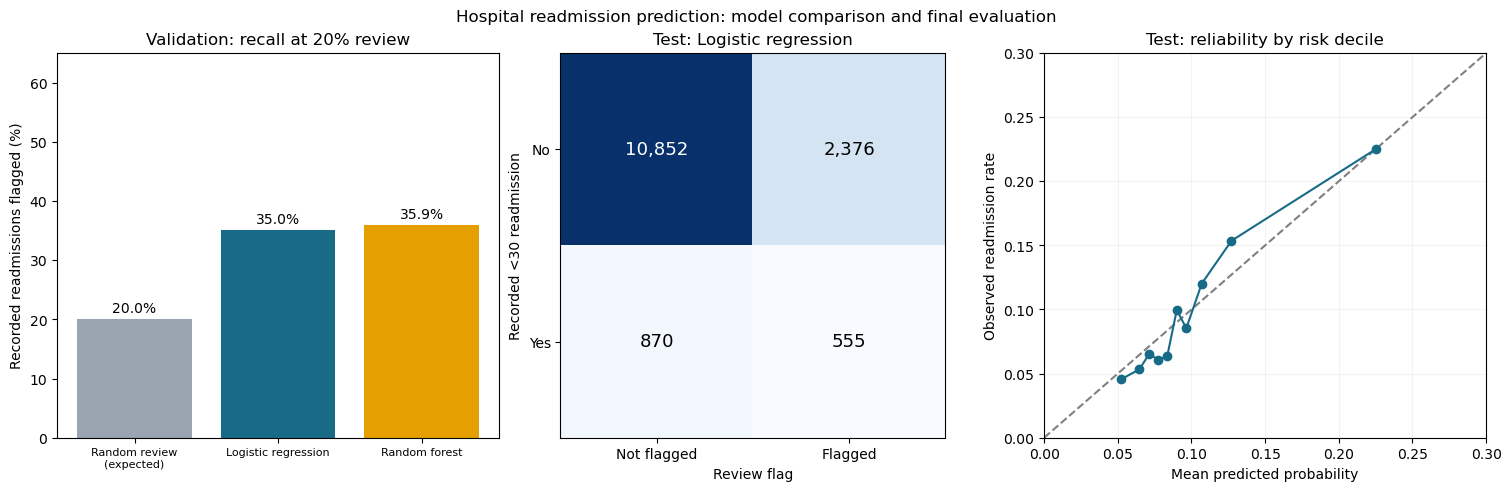

In [58]:
test_calibration = pd.DataFrame({"probability": test_scores, "outcome": y_test})
test_calibration["bin"] = pd.qcut(test_calibration["probability"], q=10, duplicates="drop")
test_calibration_bins = test_calibration.groupby("bin", observed=True).agg(
    encounters=("outcome", "size"),
    readmissions=("outcome", "sum"),
    mean_predicted_probability=("probability", "mean"),
    observed_readmission_rate=("outcome", "mean"),
).reset_index(drop=True)
assert test_calibration_bins["encounters"].sum() == len(test)
test_calibration_bins.to_csv(report_dir / "test_calibration_bins.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
names = validation_comparison["model"].str.replace("Prevalence baseline", "Random review\n(expected)")
bars = axes[0].bar(names, validation_comparison["recall_at_capacity"] * 100, color=["#9AA5B1", "#176B87", "#E69F00"])
axes[0].bar_label(bars, fmt="%.1f%%", padding=3)
axes[0].set(title="Validation: recall at 20% review", ylabel="Recorded readmissions flagged (%)", ylim=(0, 65))
axes[0].tick_params(axis="x", labelsize=8)

matrix = np.array([
    [test_capacity_values["true_negatives"], test_capacity_values["false_positives"]],
    [test_capacity_values["false_negatives"], test_capacity_values["true_positives"]],
])
axes[1].imshow(matrix, cmap="Blues")
for (row, column), value in np.ndenumerate(matrix):
    axes[1].text(column, row, f"{value:,}", ha="center", va="center", fontsize=13, color="white" if value > matrix.max() * 0.5 else "black")
axes[1].set(
    title=f"Test: {selected_name}", xlabel="Review flag", ylabel="Recorded <30 readmission",
    xticks=[0, 1], xticklabels=["Not flagged", "Flagged"],
    yticks=[0, 1], yticklabels=["No", "Yes"],
)
limit = max(0.3, test_calibration_bins[["mean_predicted_probability", "observed_readmission_rate"]].max().max() * 1.15)
axes[2].plot([0, limit], [0, limit], "--", color="gray")
axes[2].plot(test_calibration_bins["mean_predicted_probability"], test_calibration_bins["observed_readmission_rate"], "o-", color="#176B87")
axes[2].set(title="Test: reliability by risk decile", xlabel="Mean predicted probability", ylabel="Observed readmission rate", xlim=(0, limit), ylim=(0, limit))
axes[2].grid(alpha=0.15)
fig.suptitle("Hospital readmission prediction: model comparison and final evaluation")
figure_path = report_dir / "final_model_evaluation.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## Final interpretation

This is a historical, encounter-level prediction exercise for a defined home-discharge cohort. The random forest was judged using validation data and the written selection rule; the final approach was evaluated on reserved test patients. Patient-bootstrap intervals reflect test-sample variation conditional on the fixed model. They do not validate transport to modern practice.

Flagged encounters without a recorded readmission are false positives under the dataset label, not proof that follow-up is unnecessary. A risk score does not identify preventable readmissions or establish that an intervention will help. Admission history and encounter totals are useful only if available at the intended prediction time. Follow-up completeness and planned-versus-unplanned status remain unresolved.

The final result should be reported even if improvement is small. Do not tune or replace the model using these test outcomes. Future improvements require a new evaluation design or new independent data.

**Portfolio presentation:** Aggregate validation comparison, final metrics with intervals, confusion counts, reliability bins and exploratory subgroup summaries are available under `reports/`. They are suitable inputs for a Tableau companion; no patient-level scores or IDs are exported in these reports. A local [Tableau companion](tableau/Hospital_Readmissions_Dashboard_Verified.twbx) displays the aggregate results; it is a snapshot rather than a live connection to rerun outputs.

Reference: [scikit-learn RandomForestClassifier](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.RandomForestClassifier.html).